In [251]:
import numpy as np
import six
import katdal
import matplotlib.pylab as plt
import xarray as xr
from pathlib import Path
import pandas as pd
import katdal
import zarr
from dask.diagnostics import ProgressBar
#from katdal.flags import NAMES as 
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [252]:
rdb = pd.read_csv('uhf_rdb_files.csv')
rdb['CBID'] = rdb['CBID'].astype(str)

In [253]:
# Directory containing your Zarr files
zarr_dir = Path("zarrfiles/")
# Get all folders/files ending with .zarr
zarr_files = sorted([f for f in zarr_dir.iterdir() if f.suffix == ".zarr"])

In [254]:
zarr_files=zarr_files[1:]

zarr_df = pd.DataFrame({'zarr_path': zarr_files})
# Extract CBID from filename
zarr_df['CBID'] = zarr_df['zarr_path'].astype(str).str.extract(r'(\d{10})').astype('str')
cbid_array = zarr_df['CBID'].values

In [255]:
filtered_df = rdb[rdb['CBID'].isin(cbid_array)]

In [256]:
#filtered_df.to_csv('files_2_process.csv')

In [257]:
zarr_df = zarr_df.merge(filtered_df[['CBID', 'obs_hours', 'start_time']], on='CBID', how='left')

In [258]:
obs_map = zarr_df.set_index('zarr_path')['obs_hours']

In [259]:
#zarr_df['start_time'][0] = '2025-11-26 18:02:27.660+00:00'
#zarr_df['obs_hours'][0] = 3.28
#zarr_df['start_time'] =  pd.to_datetime(zarr_df['start_time'])

In [260]:
#example_z = xr.open_zarr(zarr_files[0], chunks={}, consolidated=False)

In [261]:
# m = example_z.master.sum(dim=['time', 'baseline', 'azimuth', 'elevation'])
# c = example_z.counter.sum(dim=['time', 'baseline', 'azimuth', 'elevation'])
# p = m/c
# p = p.compute()

In [299]:
import xarray as xr
import numpy as np
import pandas as pd

def compute_rfi(zarr_files, collapse_axes):
    """
    Compute RFI statistics from multiple Zarr files.

    Returns:
    --------
    - If 1 remaining dim → pandas.DataFrame
    - If 2 remaining dims → xarray.DataArray (stacked over files)
    """

    # Open example to inspect dimensions
    example_z = xr.open_zarr(zarr_files[0], chunks={}, consolidated=False)
    all_dims = list(example_z.master.dims)

    remaining_dims = [d for d in all_dims if d not in collapse_axes]

    if len(remaining_dims) == 0:
        raise ValueError("collapse_axes removed all dimensions.")

    elif len(remaining_dims) > 2:
        raise ValueError("Function supports only up to 2 remaining dimensions.")

    # -------------------------
    # CASE 1: 1D → DataFrame
    # -------------------------
    if len(remaining_dims) == 1:
        index_dim = remaining_dims[0]
        index_values = example_z[index_dim].values

        df = pd.DataFrame(index=index_values)
        df.index.name = index_dim

        for i, file in enumerate(zarr_files):
            if i % 10 == 0:
                print("Adding file", file)

            z = xr.open_zarr(file, chunks={}, consolidated=False)

            m = z.master.sum(dim=collapse_axes)
            c = z.counter.sum(dim=collapse_axes)

            with np.errstate(divide='ignore', invalid='ignore'):
                rfi = (m / c).compute().values
                rfi[np.isnan(rfi)] = np.nan

            df[file] = pd.Series(rfi, index=z[index_dim].values)

        return df

    # -------------------------
    # CASE 2: 2D → xarray
    # -------------------------
    elif len(remaining_dims) == 2:
        data_list = []

        for i, file in enumerate(zarr_files):
            if i % 10 == 0:
                print("Processing file", file)

            z = xr.open_zarr(file, chunks={}, consolidated=False)

            m = z.master.sum(dim=collapse_axes)
            c = z.counter.sum(dim=collapse_axes)

            with np.errstate(divide='ignore', invalid='ignore'):
                rfi = (m / c)

            # Keep it lazy (important!)
            rfi = rfi.where(c != 0)

            # Add file as a new dimension
            rfi = rfi.expand_dims({"file": [str(file)]})

            data_list.append(rfi)

        # Concatenate along new "file" dimension
        combined = xr.concat(data_list, dim="file")

        # Optional: enforce consistent dim order
        combined = combined.transpose("file", *remaining_dims)

        return combined

In [262]:
# def compute_rfi_dataframe(zarr_files, collapse_axes):
#     """
#     Compute RFI statistics per chosen dimension from multiple Zarr files.

#     Parameters
#     ----------
#     zarr_files : list of Path or str
#         Paths to Zarr stores.
#     collapse_axes : list of str
#         Dimensions to sum over. The remaining dimension will be used as the DataFrame index.

#     Returns
#     -------
#     df : pandas.DataFrame
#         DataFrame with index = the dimension not collapsed, columns = each Zarr file.
#     """

#     # Determine the dimension that will be used as the index
#     example_z = xr.open_zarr(zarr_files[0], chunks={}, consolidated=False)
#     all_dims = list(example_z.master.dims)
#     index_dim = [d for d in all_dims if d not in collapse_axes]
#     if len(index_dim) != 1:
#         raise ValueError("collapse_axes must leave exactly one dimension for the index.")
#     index_dim = index_dim[0]

#     # Create index from the first file
#     index_values = example_z[index_dim].values
#     df = pd.DataFrame(index=index_values)
#     df.index.name = index_dim

#     for i, file in enumerate(zarr_files):
#         if i%10 == 0:
#             print("Adding file", file)
#         z = xr.open_zarr(file, chunks={}, consolidated=False)

#         # Sum over collapse_axes
#         m = z.master.sum(dim=collapse_axes)
#         c = z.counter.sum(dim=collapse_axes)

#         # Compute fraction safely
#         with np.errstate(divide='ignore', invalid='ignore'):
#             rfi = (m / c).compute().values
#             rfi[np.isnan(rfi)] = np.nan

#         # Add to DataFrame (auto-aligns if indices match)
#         df[file] = pd.Series(rfi, index=z[index_dim].values)

#     return df

def basic_stats(df, obs_map=None):
    
    mean_rfi = df.mean(axis=1, skipna=True)
    std_rfi  = df.std(axis=1, skipna=True)
    count    = df.count(axis=1)
    median_rfi = df.median(axis=1, skipna=True)
    p25 = df.quantile(0.25, axis=1)
    p75 = df.quantile(0.75, axis=1)
    rfi_max = df.max(axis=1, skipna=True)
    rfi_min = df.min(axis=1, skipna=True)
    coverage = count / df.shape[1]

    stats_df = pd.DataFrame({
        "mean": mean_rfi,
        "std": std_rfi,
        "median": median_rfi,
        "p25": p25,
        "p75": p75,
        "min": rfi_min,
        "max": rfi_max,
        "count": count,
        "coverage": coverage
    })

    # Add weighted mean if weights provided
    if obs_map is not None:
        weights = df.columns.map(obs_map).values
        weights = weights / np.nansum(weights)
        weights = np.array(weights)

        weighted_mean = np.nansum(df.values * weights, axis=1) / np.nansum(
            (~np.isnan(df.values)) * weights, axis=1
        )

        stats_df["weighted_mean"] = weighted_mean

    return stats_df

In [323]:
def plot_1d(df_stats, xlabel):
    
    if "time" in xlabel.lower():
        df_stats["time_utc"] = pd.to_datetime(df_stats.index * 10, unit="m").strftime('%H:%M')
        df_stats = df_stats.set_index("time_utc")
    
    if "baseline" in xlabel.lower():
        bl_df = pd.read_csv('meerkatbaselinelengh.csv')
        col_name = bl_df.columns.values[0]
        bl_df = bl_df.drop(columns=col_name)
        idx = np.argsort(bl_df.values)[0]
        bl_len = bl_df.values[0][idx]
        
        weighted_mean = df_stats['weighted_mean']
        mean_rfi = df_stats['mean'].iloc[idx.tolist()]
        std_rfi = df_stats['std'].iloc[idx.tolist()]
        median_rfi = df_stats['median'].iloc[idx.tolist()]
        p25 = df_stats['p25'].iloc[idx.tolist()]
        p75 =df_stats['p75'].iloc[idx.tolist()]
        x = bl_len
    else:
        weighted_mean = df_stats['weighted_mean']
        mean_rfi = df_stats['mean']
        std_rfi = df_stats['std']
        median_rfi = df_stats['median']
        p25 = df_stats['p25']
        p75 = df_stats['p75']
        x = df_stats.index

    plt.figure(figsize=(12,5))
   
    plt.plot(x, weighted_mean, label="Weighted Mean RFI", linewidth=2)
    # Std shading
    plt.fill_between(
        x,
        weighted_mean - std_rfi,
        weighted_mean + std_rfi,
        alpha=0.2,
        label="±1 Std Dev"
    )
    # Median (robust reference)
    plt.plot(x, median_rfi, linestyle='--', label="Median")
    # IQR shading (better than std sometimes)
    plt.fill_between(
        x,
        p25,
        p75,
        alpha=0.2,
        label="IQR (25–75%)"
    )
    # Reduce ticks (every hour)
    if "time" in xlabel.lower():
        # Try to convert to HH:MM if not already strings
        if not isinstance(x[0], str):
            x_labels = pd.to_datetime(x).strftime("%H:%M")
        else:
            x_labels = x
        # Show every Nth tick (e.g., every hour)
        step = max(1, len(x_labels)//12)  # roughly 12 ticks
        plt.xticks(ticks=range(0, len(x_labels), step),
                   labels=x_labels[::step],
                   rotation=45)
    else:
        plt.xticks(rotation=0)
    plt.ylabel("RFI Fraction")
    plt.xlabel(xlabel)
    plt.title("UHF RFI Environment")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    return

In [300]:
freq_time_dim = ['baseline', 'azimuth', 'elevation']
freq_time_df = compute_rfi(zarr_files, freq_time_dim)

Processing file zarrfiles/1648747634_sdp_l0.full.zarr
Processing file zarrfiles/1680914508_sdp_l0.full.zarr
Processing file zarrfiles/1696220177_sdp_l0.full.zarr
Processing file zarrfiles/1708896079_sdp_l0.full.zarr
Processing file zarrfiles/1741615626_sdp_l0.full.zarr
Processing file zarrfiles/1747164316_sdp_l0.full.zarr
Processing file zarrfiles/1753233670_sdp_l0.full.zarr
Processing file zarrfiles/1758896191_sdp_l0.full.zarr
Processing file zarrfiles/1762446670_sdp_l0.full.zarr
Processing file zarrfiles/1764816197_sdp_l0.full.zarr
Processing file zarrfiles/1767463275_sdp_l0.full.zarr
Processing file zarrfiles/1768254556_sdp_l0.full.zarr
Processing file zarrfiles/1770600067_sdp_l0.full.zarr


/scratch/isihlangu/py3/lib/python3.10/site-packages/dask/array/core.py:5003: PerformanceWarning: Increasing number of chunks by factor of 16
  result = blockwise(
/scratch/isihlangu/py3/lib/python3.10/site-packages/dask/array/core.py:5003: PerformanceWarning: Increasing number of chunks by factor of 16
  result = blockwise(
/scratch/isihlangu/py3/lib/python3.10/site-packages/dask/array/core.py:5003: PerformanceWarning: Increasing number of chunks by factor of 16
  result = blockwise(
/scratch/isihlangu/py3/lib/python3.10/site-packages/dask/array/core.py:5003: PerformanceWarning: Increasing number of chunks by factor of 16
  result = blockwise(
/scratch/isihlangu/py3/lib/python3.10/site-packages/dask/array/core.py:5003: PerformanceWarning: Increasing number of chunks by factor of 16
  result = blockwise(
/scratch/isihlangu/py3/lib/python3.10/site-packages/dask/array/core.py:5003: PerformanceWarning: Increasing number of chunks by factor of 16
  result = blockwise(
/scratch/isihlangu/py3

In [264]:
time_dim = ['frequency', 'baseline', 'azimuth', 'elevation']
df_time = compute_rfi_dataframe(zarr_files, time_dim)

Adding file zarrfiles/1648747634_sdp_l0.full.zarr
Adding file zarrfiles/1680914508_sdp_l0.full.zarr
Adding file zarrfiles/1696220177_sdp_l0.full.zarr
Adding file zarrfiles/1708896079_sdp_l0.full.zarr
Adding file zarrfiles/1741615626_sdp_l0.full.zarr
Adding file zarrfiles/1747164316_sdp_l0.full.zarr
Adding file zarrfiles/1753233670_sdp_l0.full.zarr
Adding file zarrfiles/1758896191_sdp_l0.full.zarr
Adding file zarrfiles/1762446670_sdp_l0.full.zarr
Adding file zarrfiles/1764816197_sdp_l0.full.zarr
Adding file zarrfiles/1767463275_sdp_l0.full.zarr


/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

Adding file zarrfiles/1768254556_sdp_l0.full.zarr


/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

Adding file zarrfiles/1770600067_sdp_l0.full.zarr


/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

In [265]:
time_stats = basic_stats(df_time, obs_map)

In [290]:
time_stats.to_csv("time_stats.csv")

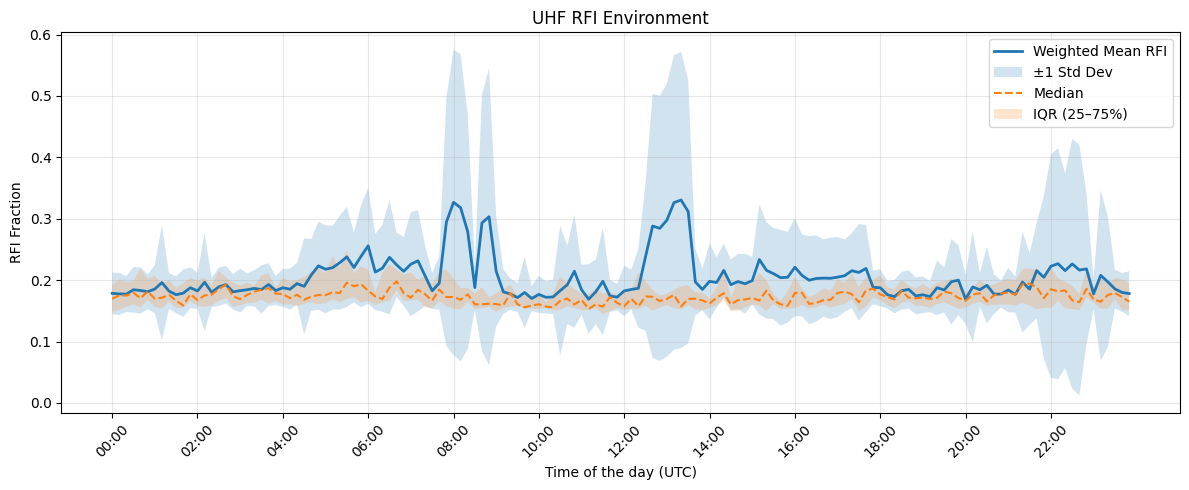

In [324]:
plot_1d(time_stats, "Time of the day (UTC)")

In [475]:
def compute_percentile_vectorized(df, new_obs):
    new_obs = new_obs.squeeze()

    percentiles = []
    min_samples = 5

    for t in df.index:
        hist = df.loc[t].dropna()

        

        hist = df.loc[t].dropna()
        
        if len(hist) < min_samples:
            percentiles.append(np.nan)
            continue

        percentiles.append((hist <= new_obs.loc[t]).mean())

    return pd.Series(percentiles, index=df.index)

In [471]:
new_obs = pd.DataFrame(df_time[df_time.columns[0]])

In [472]:
percentiles = compute_percentile_vectorized(df_time.iloc[:, 1:], new_obs)

In [473]:
anomalous_bins = percentiles > 0.9

# fraction of anomalous time bins
frac_anomalous = np.nanmean(anomalous_bins)cd 

flag = frac_anomalous > 0.1

print("Fraction anomalous: {}%".format(frac_anomalous*100))
print("Flagged:", flag)

Fraction anomalous: 4.861111111111112%
Flagged: False


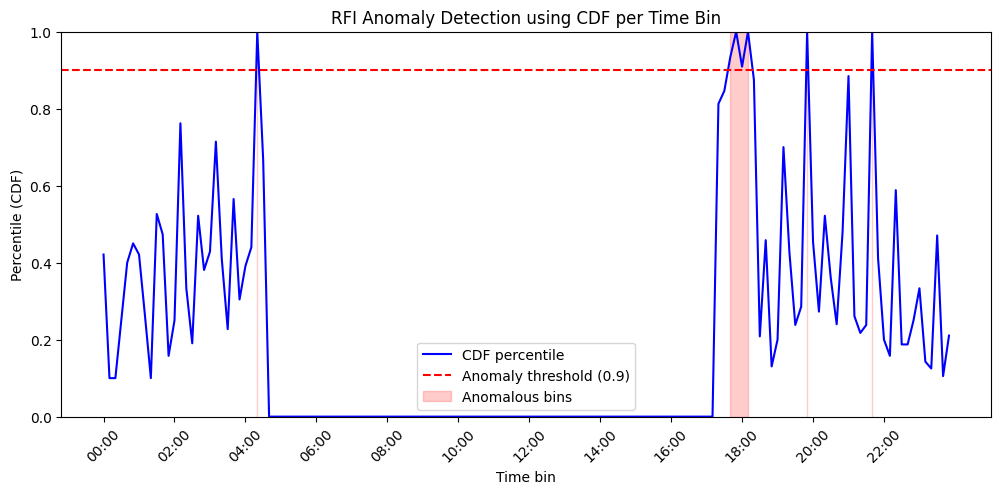

In [474]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 5))

# percentiles over time
plt.plot(percentiles, label="CDF percentile", color="blue")
x = time_stats.index
x_labels = x
step = max(1, len(x_labels)//12)  # roughly 12 ticks
plt.xticks(ticks=range(0, len(x_labels), step),
                   labels=x_labels[::step],
                   rotation=45)

# threshold line
plt.axhline(0.9, color="red", linestyle="--", label="Anomaly threshold (0.9)")

# highlight flagged regions
plt.fill_between(
    range(len(percentiles)),
    0,
    1,
    where=anomalous_bins,
    color="red",
    alpha=0.2,
    label="Anomalous bins"
)

plt.ylim(0, 1)
plt.xlabel("Time bin")
plt.ylabel("Percentile (CDF)")
plt.title("RFI Anomaly Detection using CDF per Time Bin")
plt.legend()

plt.show()

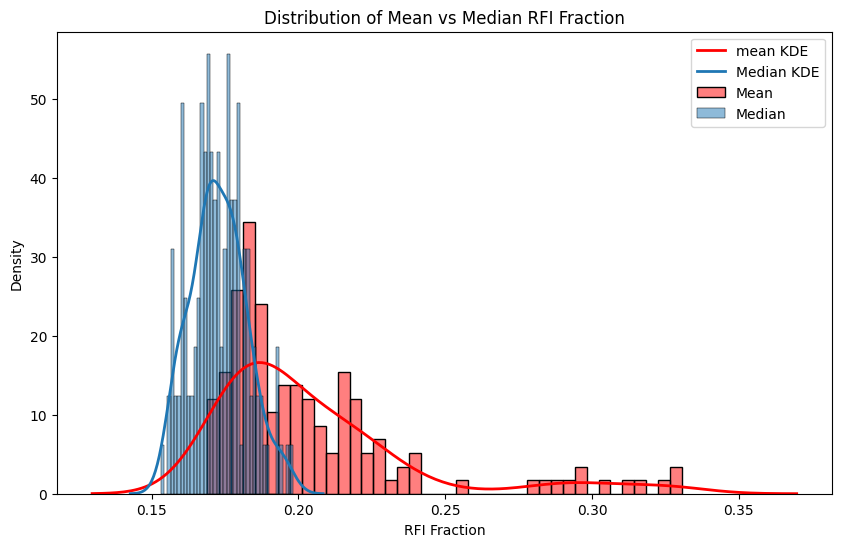

In [330]:
mean_vals = time_stats['weighted_mean']
median_vals = time_stats['median'],
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.histplot(mean_vals , bins=40, color='red', alpha=0.5, label='Mean', stat="density")
sns.histplot(median_vals, bins=40, color='blue', alpha=0.5, label='Median', stat="density")
sns.kdeplot(mean_vals , color='red', linewidth=2, label='mean KDE')
sns.kdeplot(median_vals, color='blue', linewidth=2, label='Median KDE')

plt.xlabel("RFI Fraction")
plt.ylabel("Density")
plt.title("Distribution of Mean vs Median RFI Fraction")
plt.legend()

plt.show()

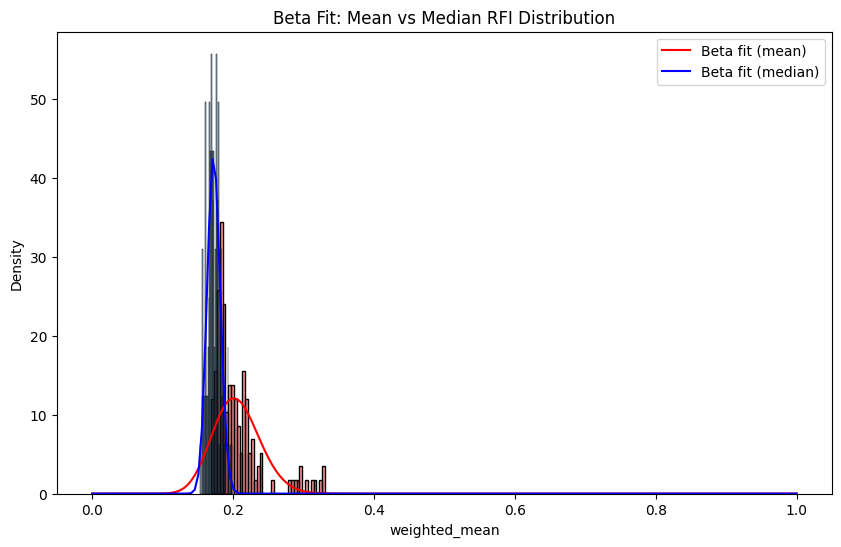

In [469]:
from scipy.stats import beta

eps = 1e-6

mean_clip = np.clip(mean_vals, eps, 1 - eps)
median_clip = np.clip(median_vals, eps, 1 - eps)

a1, b1, _, _ = beta.fit(mean_clip, floc=0, fscale=1)
a2, b2, _, _ = beta.fit(median_clip, floc=0, fscale=1)

x = np.linspace(0, 1, 200)

plt.figure(figsize=(10, 6))

sns.histplot(mean_vals, bins=40, stat="density", alpha=0.4, color='red')
sns.histplot(median_vals, bins=40, stat="density", alpha=0.4, color='blue')

plt.plot(x, beta.pdf(x, a1, b1), 'r-', label='Beta fit (mean)')
plt.plot(x, beta.pdf(x, a2, b2), 'b-', label='Beta fit (median)')

plt.legend()
plt.title("Beta Fit: Mean vs Median RFI Distribution")

plt.show()

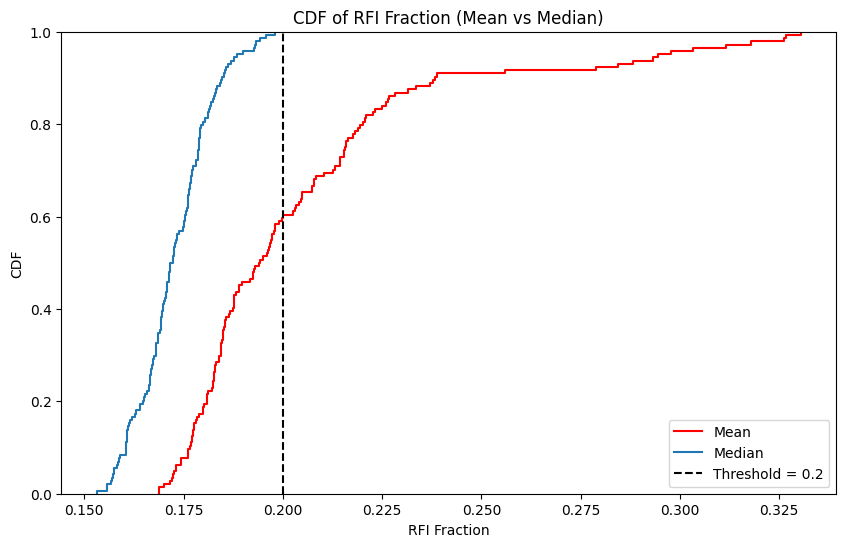

In [470]:
import seaborn as sns
import matplotlib.pyplot as plt

threshold = 0.2

plt.figure(figsize=(10, 6))

sns.ecdfplot(mean_vals, label="Mean", color='red')
sns.ecdfplot(median_vals, label="Median", color='blue')

plt.axvline(threshold, color='black', linestyle='--', label=f"Threshold = {threshold}")

plt.xlabel("RFI Fraction")
plt.ylabel("CDF")
plt.title("CDF of RFI Fraction (Mean vs Median)")
plt.legend()

plt.show()

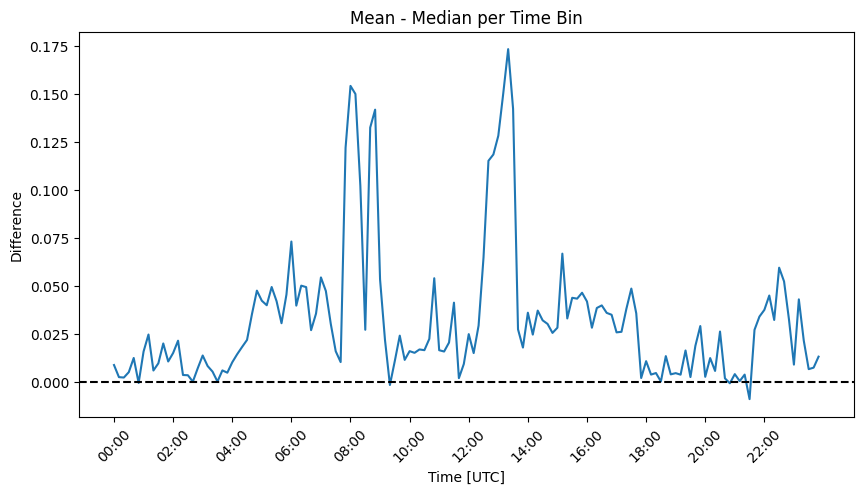

In [329]:
diff = time_stats["weighted_mean"] - time_stats["median"]
#time_stats["time_utc"] = pd.to_datetime(time_stats.index * 10, unit="m").strftime('%H:%M')
#time_stats = time_stats.set_index("time_utc")
x = time_stats.index
x_labels = x
        
plt.figure(figsize=(10, 5))
plt.plot(diff)
plt.axhline(0, color='black', linestyle='--')
step = max(1, len(x_labels)//12)  # roughly 12 ticks
plt.xticks(ticks=range(0, len(x_labels), step),
                   labels=x_labels[::step],
                   rotation=45)
plt.title("Mean - Median per Time Bin")
plt.ylabel("Difference")
plt.xlabel("Time [UTC]")

plt.show()

In [267]:
freq_dim = ['time', 'baseline', 'azimuth', 'elevation']

In [268]:
df_freq = compute_rfi_dataframe(zarr_files, freq_dim)

Adding file zarrfiles/1648747634_sdp_l0.full.zarr
Adding file zarrfiles/1680914508_sdp_l0.full.zarr
Adding file zarrfiles/1696220177_sdp_l0.full.zarr
Adding file zarrfiles/1708896079_sdp_l0.full.zarr
Adding file zarrfiles/1741615626_sdp_l0.full.zarr
Adding file zarrfiles/1747164316_sdp_l0.full.zarr
Adding file zarrfiles/1753233670_sdp_l0.full.zarr
Adding file zarrfiles/1758896191_sdp_l0.full.zarr
Adding file zarrfiles/1762446670_sdp_l0.full.zarr
Adding file zarrfiles/1764816197_sdp_l0.full.zarr
Adding file zarrfiles/1767463275_sdp_l0.full.zarr


/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

Adding file zarrfiles/1768254556_sdp_l0.full.zarr


/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

Adding file zarrfiles/1770600067_sdp_l0.full.zarr


/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

In [293]:
df_freq.to_csv('freq.csv')

In [269]:
freq_stats = basic_stats(df_freq, obs_map)

In [292]:
freq_stats.to_csv('freq_stats.csv')

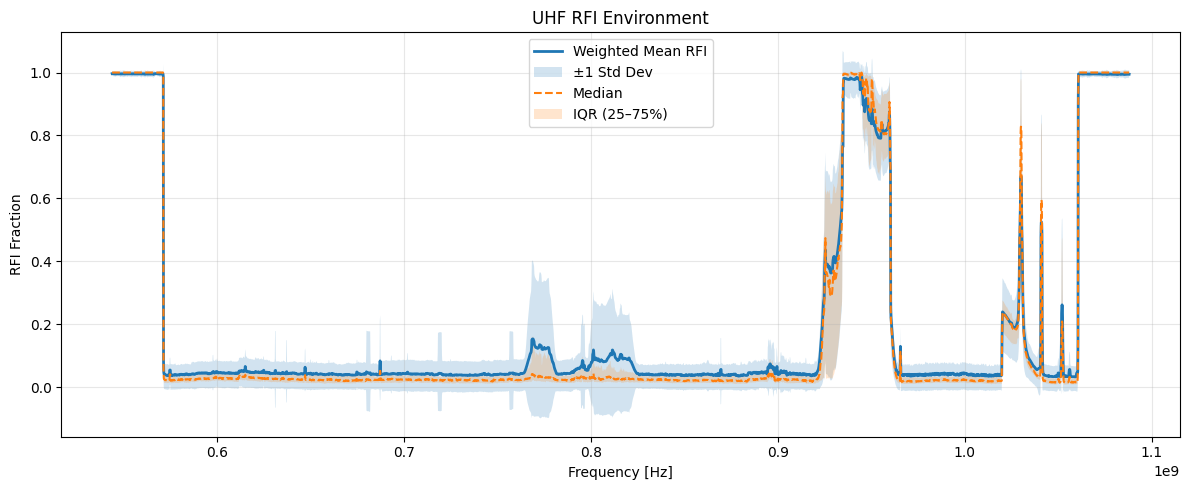

In [304]:
plot_1d(freq_stats, "Frequency [Hz]")

In [271]:
baseline_dim = ['time', 'frequency', 'azimuth', 'elevation']
df_baseline = compute_rfi_dataframe(zarr_files, baseline_dim)

Adding file zarrfiles/1648747634_sdp_l0.full.zarr
Adding file zarrfiles/1680914508_sdp_l0.full.zarr
Adding file zarrfiles/1696220177_sdp_l0.full.zarr
Adding file zarrfiles/1708896079_sdp_l0.full.zarr
Adding file zarrfiles/1741615626_sdp_l0.full.zarr
Adding file zarrfiles/1747164316_sdp_l0.full.zarr
Adding file zarrfiles/1753233670_sdp_l0.full.zarr
Adding file zarrfiles/1758896191_sdp_l0.full.zarr
Adding file zarrfiles/1762446670_sdp_l0.full.zarr
Adding file zarrfiles/1764816197_sdp_l0.full.zarr
Adding file zarrfiles/1767463275_sdp_l0.full.zarr


/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

Adding file zarrfiles/1768254556_sdp_l0.full.zarr


/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

Adding file zarrfiles/1770600067_sdp_l0.full.zarr


/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[file] = pd.Series(rfi, index=z[index_dim].values)
/tmp/ipykernel_1707408/1639323454.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

In [272]:
baseline_stats = basic_stats(df_baseline, obs_map)

In [295]:
df_baseline.to_csv("baseline.csv")
baseline_stats.to_csv("baseline_stats.csv")

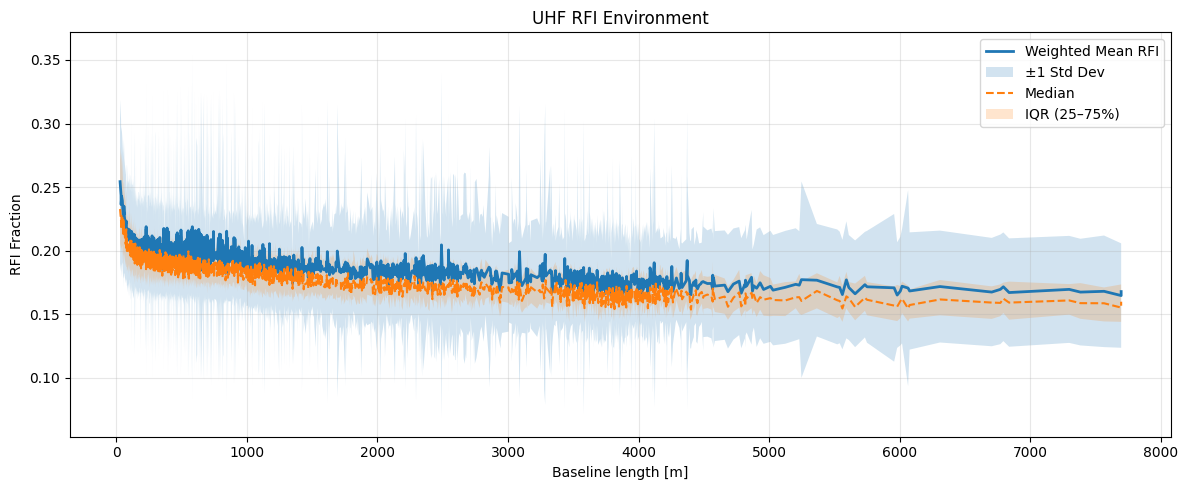

In [273]:
plot_1d(baseline_stats, "Baseline length [m]")

In [274]:
def rfi_heatmap(zarr_files, obs_df, collapse_axes=['time', 'baseline', 'azimuth', 'elevation']):
    """
    Compute RFI per frequency per observation and create a heatmap.

    Parameters
    ----------
    zarr_files : list of str or Path
        Paths to Zarr stores.
    obs_df : pandas.DataFrame
        Must have columns ['CBID','obs_date'] (obs_date as datetime).
    collapse_axes : list of str
        Dimensions to sum over (keep 'frequency').

    Returns
    -------
    rfi_df : pandas.DataFrame
        Frequencies as rows, sorted observation CBIDs as columns.
    """

    # Sort observations by date
    obs_df_sorted = obs_df.sort_values('start_time').reset_index(drop=True)
    sorted_cbids = obs_df_sorted['CBID'].astype(str).tolist()

    rfi_data = {}
    freq_index = None

    for file in zarr_files:
        cbid = file.stem.split('_')[0]  # Extract CBID from zarr filename
        if cbid not in sorted_cbids:
            continue  # skip files not in your dataframe

        z = xr.open_zarr(file, chunks={}, consolidated=False)
        # Sum over collapse_axes
        m = z.master.sum(dim=collapse_axes)
        c = z.counter.sum(dim=collapse_axes)

        with np.errstate(divide='ignore', invalid='ignore'):
            rfi = (m / c).compute().values
            rfi[np.isnan(rfi)] = np.nan

        # Store RFI per frequency
        rfi_data[cbid] = rfi
        if freq_index is None:
            freq_index = z.frequency.values/1e6

    # Build DataFrame
    rfi_df = pd.DataFrame(rfi_data, index=freq_index)
    rfi_df = rfi_df[sorted_cbids]  # ensure columns sorted by obs_date

    return rfi_df



def plot_rfi_heatmap(rfi_df, obs_df, labels=None):
    # Align metadata
    obs_df = obs_df.set_index('CBID').loc[rfi_df.columns]

    time_labels = pd.to_datetime(obs_df['start_time']).dt.strftime('%Y-%m-%d %H:%M:%S')
    cbid_labels = obs_df.index.astype(str)

    fig, ax = plt.subplots(figsize=(12,6))
    plt.subplots_adjust(right=0.88)

    index = rfi_df.index

    im = ax.imshow(
        rfi_df.T,
        aspect='auto',
        origin='lower',
        cmap="inferno",
        interpolation="nearest",
        extent=[index[0], index[-1], 0, rfi_df.shape[1]]
    )

    # Y positions
    y_positions = np.arange(len(cbid_labels))
    step = max(1, len(y_positions)//10)

    # Left axis → TIME
    ax.set_yticks(y_positions[::step])
    ax.set_yticklabels(time_labels[::step])
    ax.set_ylabel("Observation Time (UTC)")

    # Right axis → CBID
    ax2 = ax.twinx()
    ax2.set_ylim(ax.get_ylim())
    ax2.set_yticks(y_positions[::step])
    ax2.set_yticklabels(cbid_labels[::step])
    ax2.set_ylabel("CBID")

    # Highlight clusters
    if labels is not None:
        # Ensure labels align with columns
        labels = np.array(labels)
        order = np.arange(len(labels))

        # Draw horizontal separators between clusters
        for i in range(1, len(labels)):
            if labels[i] != labels[i-1]:
                ax.axhline(i, color='white', linewidth=1.5)

        # Optional: subtle shading per cluster
        for i, c in enumerate(labels):
            ax.axhspan(i-0.5, i+0.5, color='white', alpha=0.03 * (c+1))

    # Colorbar (moved right)
    #cax = fig.add_axes([0.9, 0.15, 0.02, 0.7])
    fig.colorbar(im, ax=ax, label='RFI Fraction', pad=0.15)

    ax.set_xlabel("Frequency [MHz]")
    ax.set_title("RFI Heatmap (Sorted by Observation Time)")

    plt.show()

In [275]:
rfi_df = rfi_heatmap(zarr_files, zarr_df)

In [276]:
zarr_df['start_time'] = pd.to_datetime(zarr_df['start_time'])

# Format to string without microseconds
zarr_df['time_label'] = zarr_df['start_time'].dt.strftime('%Y-%m-%d %H:%M:%S')

In [277]:
rfi_df = rfi_df.dropna(axis=1, how='all')

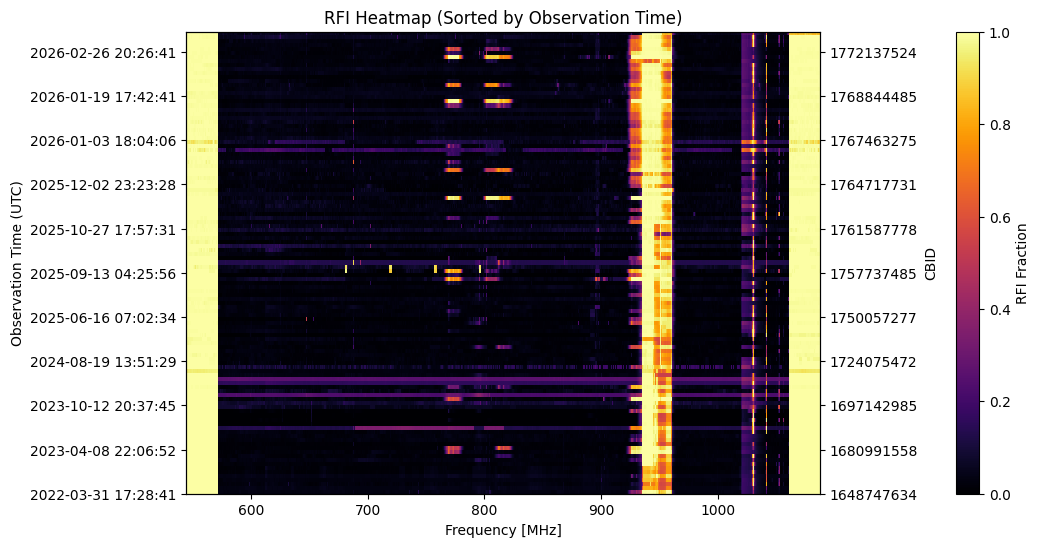

In [278]:
plot_rfi_heatmap(rfi_df, zarr_df)

In [279]:
threshold = np.median(rfi_df.values) + 2 * np.std(rfi_df.values)

In [280]:
mean_obs = rfi_df.mean(axis=1)

In [281]:
#rfi_df

In [282]:
# Fraction of observations flagged per frequency
persistence = (rfi_df > threshold).mean(axis=1)

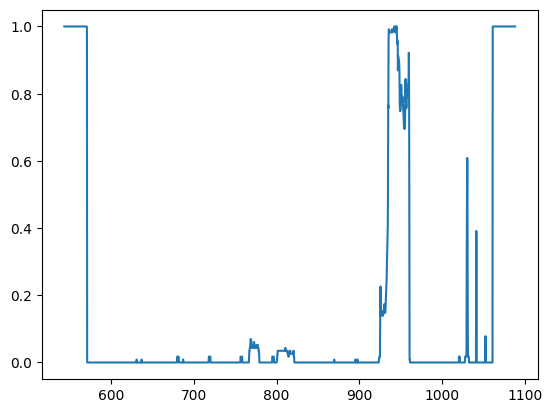

In [283]:
plt.plot(rfi_df.index, persistence)

In [284]:
# Example: variance over time per frequency
temporal_variability = rfi_df.var(axis=1)

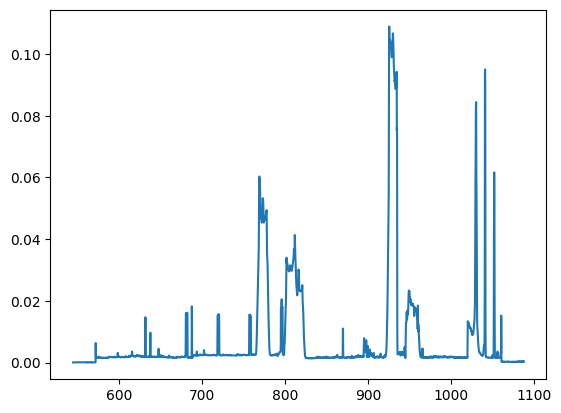

In [285]:
plt.plot(temporal_variability.index, temporal_variability)

In [286]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3)
labels = kmeans.fit_predict(rfi_df.T)

In [182]:
cluster_df = pd.DataFrame({
    "CBID": rfi_df.columns,
    "cluster": labels
})

In [183]:
cluster_df = cluster_df.merge(zarr_df, on="CBID")

In [184]:
order = np.argsort(labels)
sorted_df = rfi_df.iloc[:, order]
sorted_labels = labels[order]

In [185]:
#plot_rfi_heatmap(sorted_df, cluster_df)

In [186]:
cluster_means = {}

for c in np.unique(labels):
    cluster_means[c] = rfi_df.loc[:, labels == c].mean(axis=1)

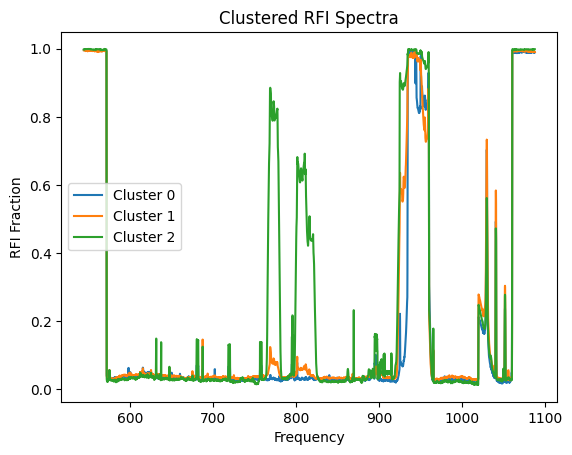

In [187]:
for c, spectrum in cluster_means.items():
    plt.plot(rfi_df.index, spectrum, label=f"Cluster {c}")

plt.legend()
plt.xlabel("Frequency")
plt.ylabel("RFI Fraction")
plt.title("Clustered RFI Spectra")
plt.show()

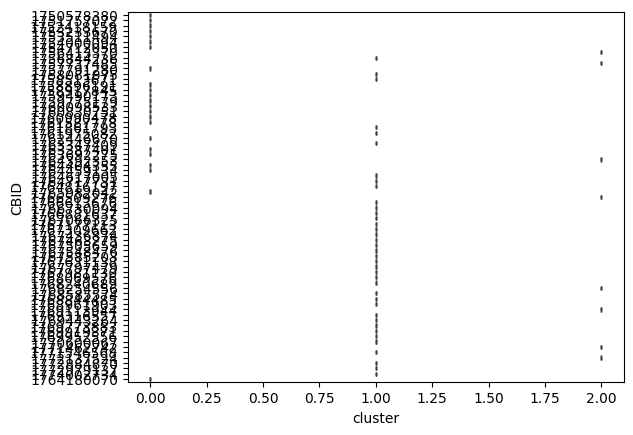

In [188]:
import seaborn as sns

sns.boxplot(data=cluster_df, x="cluster", y="CBID")
plt.show()